Loading Rice Leaf Disease Model...


config.json:   0%|          | 0.00/955 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 16.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded successfully!
Number of classes: 17

Please upload a rice leaf image:


Saving rice image.jpg to rice image.jpg


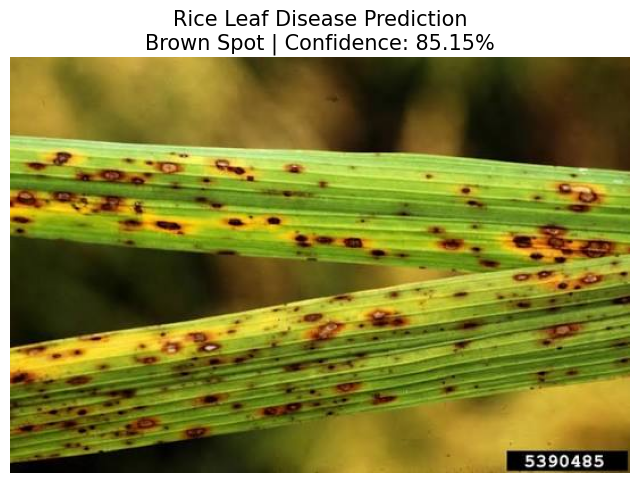



       RICE LEAF DISEASE PREDICTION
Image       : rice image.jpg
Disease     : Brown Spot
Confidence  : 85.15%

Top 5 Predictions:
--------------------------------------------------
Brown Spot                85.15%
Narrow Brown Spot         4.89%
Healthy                   1.37%
Leaf Blast                1.27%
Sheath Blight             1.24%


In [1]:
# ============================================================
# RICE LEAF DISEASE PREDICTION
# Model: Huyt/rice-leaf-disease-efficientnet-b0
# ============================================================

# Install libraries
!pip install -q timm huggingface_hub

# Imports
import torch
import timm
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. Load pretrained model
# ------------------------------------------------------------

print("Loading Rice Leaf Disease Model...")

model = timm.create_model(
    "hf_hub:Huyt/rice-leaf-disease-efficientnet-b0",
    pretrained=True
)

model.eval()

# Get model's official preprocessing
cfg = timm.data.resolve_data_config({}, model=model)
transform = timm.data.create_transform(**cfg)

print("Model loaded successfully!")
print("Number of classes:", len(model.pretrained_cfg["label_names"]))

# ------------------------------------------------------------
# 2. Upload rice leaf image
# ------------------------------------------------------------

print("\nPlease upload a rice leaf image:")

uploaded = files.upload()

image_path = next(iter(uploaded))

# Open image
image = Image.open(image_path).convert("RGB")

# ------------------------------------------------------------
# 3. Prepare image
# ------------------------------------------------------------

input_tensor = transform(image).unsqueeze(0)

# ------------------------------------------------------------
# 4. Prediction
# ------------------------------------------------------------

with torch.no_grad():

    output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)[0]

# Best prediction
predicted_index = int(probabilities.argmax())

predicted_label = model.pretrained_cfg["label_names"][predicted_index]

confidence = float(probabilities[predicted_index]) * 100

# ------------------------------------------------------------
# 5. Display image + result
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

plt.imshow(image)

plt.axis("off")

plt.title(
    f"Rice Leaf Disease Prediction\n"
    f"{predicted_label} | Confidence: {confidence:.2f}%",
    fontsize=15
)

plt.show()

# ------------------------------------------------------------
# 6. Print result
# ------------------------------------------------------------

print("\n")
print("=" * 50)
print("       RICE LEAF DISEASE PREDICTION")
print("=" * 50)

print(f"Image       : {image_path}")
print(f"Disease     : {predicted_label}")
print(f"Confidence  : {confidence:.2f}%")

print("=" * 50)

# ------------------------------------------------------------
# 7. Show Top 5 predictions
# ------------------------------------------------------------

top5_prob, top5_indices = torch.topk(probabilities, 5)

print("\nTop 5 Predictions:")
print("-" * 50)

for prob, idx in zip(top5_prob, top5_indices):

    label = model.pretrained_cfg["label_names"][int(idx)]

    percentage = float(prob) * 100

    print(f"{label:<25} {percentage:.2f}%")